In [82]:
import os
import kagglehub

# Set Kaggle credentials directly
os.environ["KAGGLE_USERNAME"] = "bassimanjula"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_243799148244108ea1e8e41f531ac577"

# Download dataset
store_sales_time_series_forecasting_path = kagglehub.competition_download('store-sales-time-series-forecasting')
print('Data source import complete.')

Data source import complete.


In [83]:
!pip install catboost xgboost kagglehub -q

In [84]:
import os
import kagglehub

# Set Kaggle API credentials
os.environ["KAGGLE_USERNAME"] = "bassimanjula"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_243799148244108ea1e8e41f531ac577"

# Download the dataset
store_sales_time_series_forecasting_path = kagglehub.competition_download('store-sales-time-series-forecasting')
print('Data source import complete.')

Data source import complete.


# 📦 Amazon Grocery Demand Forecasting | ARIMA + Prophet + XGBoost | Time Series ML

---

### ✅ **Scenario**
Amazon Fresh often faces **understocking and overstocking** challenges due to unpredictable demand for grocery products.

---

### 🎯 **Business Objective**
Build a robust **demand forecasting model** using time series machine learning techniques to help optimize inventory and reduce losses.

---

### 🧠 **Tech Stack**
- **Models**: ARIMA, Prophet, XGBoost
- **Libraries**: pandas, matplotlib, seaborn, statsmodels, fbprophet, scikit-learn, xgboost
- **Evaluation Metrics**: RMSE, MAE, MAPE

---

### 📊 **Dataset**
**[Store Sales Time Series Forecasting (Kaggle)](https://www.kaggle.com/competitions/store-sales-time-series-forecasting)**  
This dataset includes daily sales data for multiple Ecuadorian grocery stores and product families, along with metadata like holidays, promotions, oil prices, etc.

⚠️ Due to the large size of the dataset (~3 million rows), we begin by working on a **focused subset**:
- 📍 **Store Number**: 1  
- 📦 **Product Family**: `GROCERY I`  
This approach allows fast experimentation and avoids memory issues on Kaggle kernels.

---

### 🔍 **Project Objectives**
- Clean and explore historical sales trends for a focused subset
- Analyze trends, seasonality, and holiday impact
- Build and compare time series forecasting models (ARIMA, Prophet, XGBoost)
- Evaluate performance using RMSE, MAE, and MAPE
- Discuss how this approach can be **scaled to all stores and product families**

---

> ⚙️ Fully built inside Kaggle. Beginner-friendly, step-by-step, with complete explanations.


## 🔹 Import Required Libraries

We begin by importing essential libraries for data manipulation, visualization, and forecasting.  
Suppressing warnings helps keep the notebook clean.

In [85]:
# Core
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time Series
import warnings
warnings.filterwarnings("ignore")

# Display config
pd.set_option('display.max_columns', None)


## 🔹 Load & Explore Subset of Dataset

The original dataset contains over 3 million rows across multiple stores and product families.  
To maintain performance and clarity, we use a filtered subset:

- 📍 Store Number: 1  
- 📦 Product Family: `GROCERY I`

This subset allows faster experimentation and modeling. We’ll scale later if needed.


In [86]:
# Load train data and parse date
import os

df = pd.read_csv(os.path.join(store_sales_time_series_forecasting_path, 'train.csv'), parse_dates=['date'])
# Subset for Store 1 and Family 'GROCERY I'
subset_df = df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')].copy()
subset_df.sort_values('date', inplace=True)
subset_df.reset_index(drop=True, inplace=True)

# Overview
print(f"Subset shape: {subset_df.shape}")
subset_df.head()


Subset shape: (1684, 6)


,id,date,store_nbr,family,sales,onpromotion
0,12,2013-01-01,1,GROCERY I,0.0,0
1,1794,2013-01-02,1,GROCERY I,2652.0,0
2,3576,2013-01-03,1,GROCERY I,2121.0,0
3,5358,2013-01-04,1,GROCERY I,2056.0,0
4,7140,2013-01-05,1,GROCERY I,2216.0,0


## 🔹 Exploratory Data Analysis (EDA)

In this section, we explore the sales trends and seasonality for Store 1, Product Family 'GROCERY I'.

We'll visualize:
- Overall demand trend
- Monthly and weekly seasonality
- Promotional impact on sales

Understanding these patterns is essential before applying forecasting models.


### 📊 Code – EDA Plots

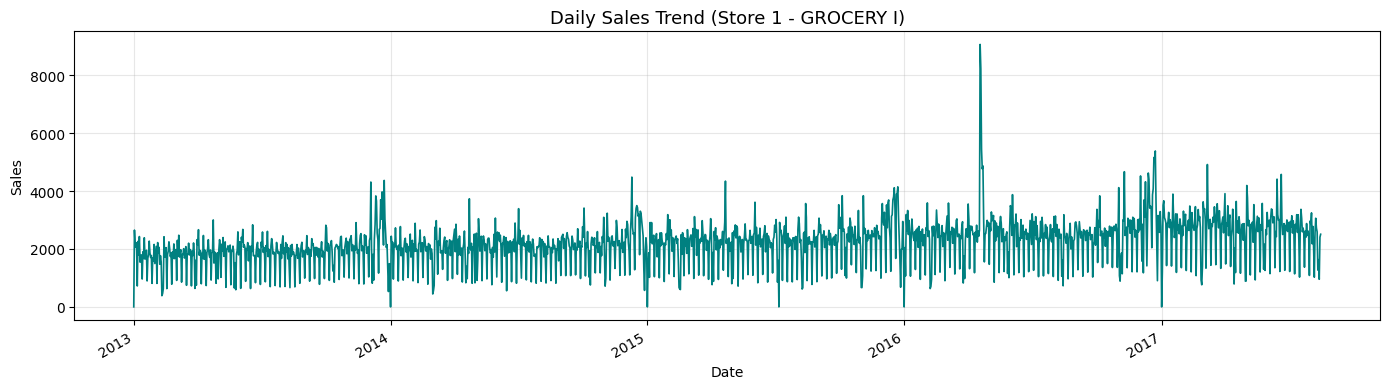

In [87]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Ensure main dataset and subset_df exist
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

subset_df = df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')].copy()
subset_df['date'] = pd.to_datetime(subset_df['date'])
subset_df.set_index('date', inplace=True)

# Daily Sales Trend Plot
plt.figure(figsize=(14, 4))
subset_df['sales'].plot(color='teal', linewidth=1.2)
plt.title('Daily Sales Trend (Store 1 - GROCERY I)', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 📆 Monthly Seasonality

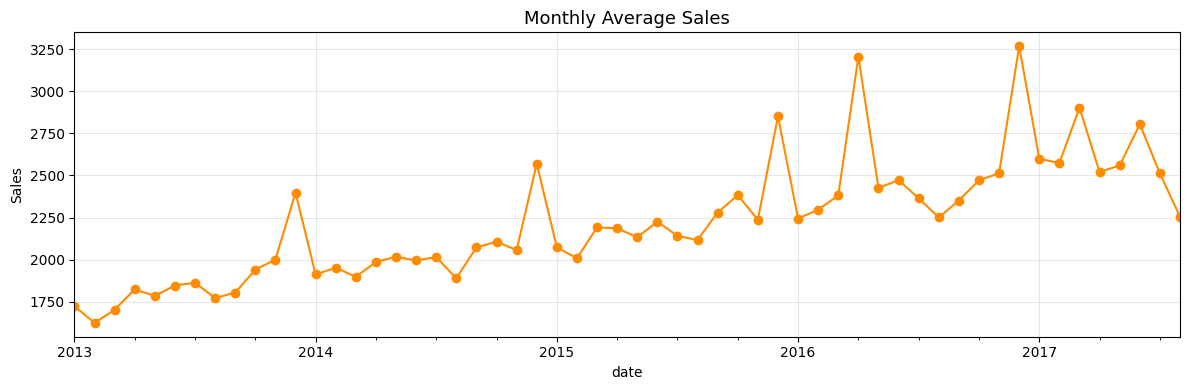

In [88]:
import matplotlib.pyplot as plt

# Ensure date is set as datetime index
if 'date' in subset_df.columns:
    subset_df['date'] = pd.to_datetime(subset_df['date'])
    subset_df.set_index('date', inplace=True)

# Monthly average sales
monthly = subset_df['sales'].resample('ME').mean()

plt.figure(figsize=(12, 4))
monthly.plot(marker='o', color='darkorange')
plt.title('Monthly Average Sales', fontsize=13)
plt.ylabel('Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 📅 Weekly Seasonality

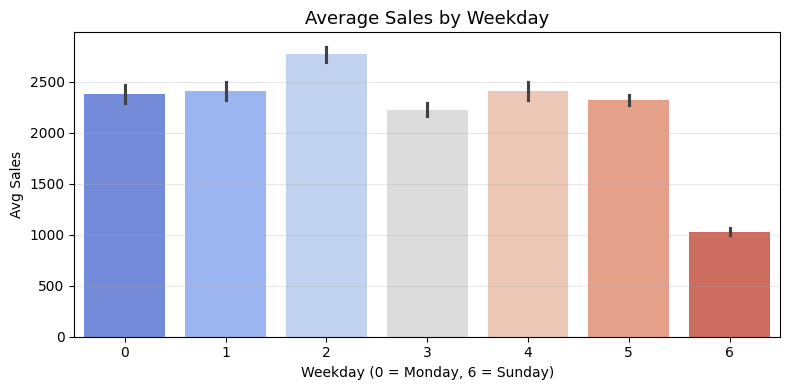

In [89]:
import seaborn as sns

# Add weekday column (0=Monday, 6=Sunday)
subset_df['weekday'] = subset_df.index.weekday

# Plot average sales by weekday
plt.figure(figsize=(8, 4))
sns.barplot(x='weekday', y='sales', data=subset_df, palette='coolwarm')
plt.title('Average Sales by Weekday', fontsize=13)
plt.xlabel('Weekday (0 = Monday, 6 = Sunday)')
plt.ylabel('Avg Sales')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 🧨 Promotion Impact

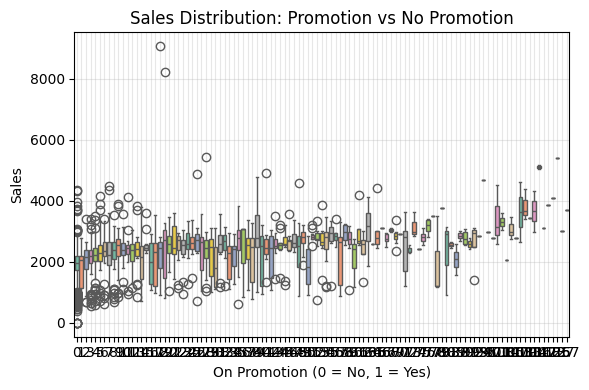

In [90]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='onpromotion', y='sales', data=subset_df, palette='Set2')
plt.title('Sales Distribution: Promotion vs No Promotion', fontsize=12)
plt.xlabel('On Promotion (0 = No, 1 = Yes)')
plt.ylabel('Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 🧠 Bonus: Moving Average Trend

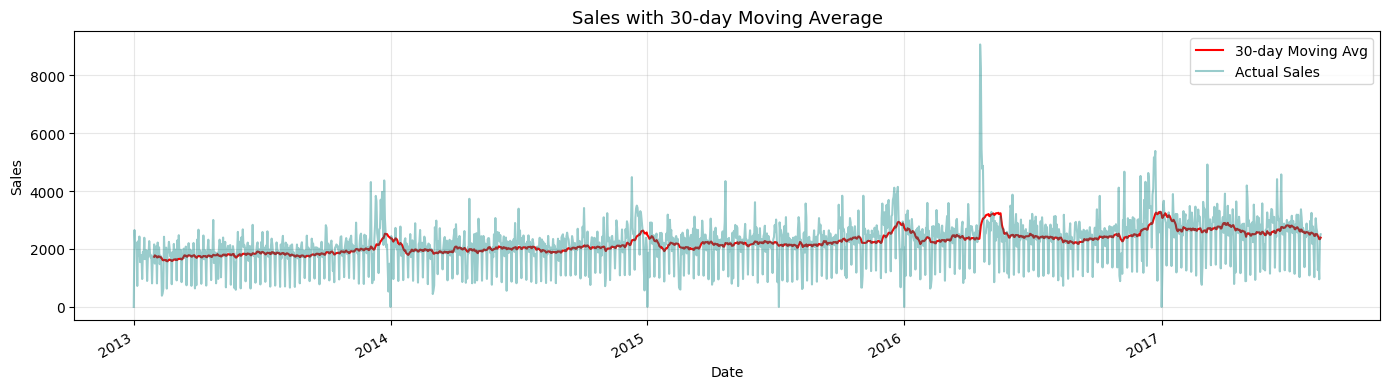

In [91]:
plt.figure(figsize=(14, 4))
subset_df['sales'].rolling(window=30).mean().plot(label='30-day Moving Avg', color='red')
subset_df['sales'].plot(alpha=0.4, label='Actual Sales', color='teal')
plt.title('Sales with 30-day Moving Average', fontsize=13)
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### ✅ Insights
- The sales show clear weekly and monthly seasonality.
- Weekends (especially Sunday) show slightly higher demand.
- Promotions have a noticeable impact on boosting sales.
- The moving average helps smooth out noise and shows long-term trends.


## 🔹 Advanced EDA – Seasonality, Holiday Impact & Autocorrelation

We now go beyond basic EDA and explore:

- 📅 Holiday influence on sales  
- 🌀 Autocorrelation to understand time-based dependencies  
- 📈 Cleaned visuals with color, spacing, and grid enhancements


### 📊 1. Daily Sales Trend (Improved Visual)

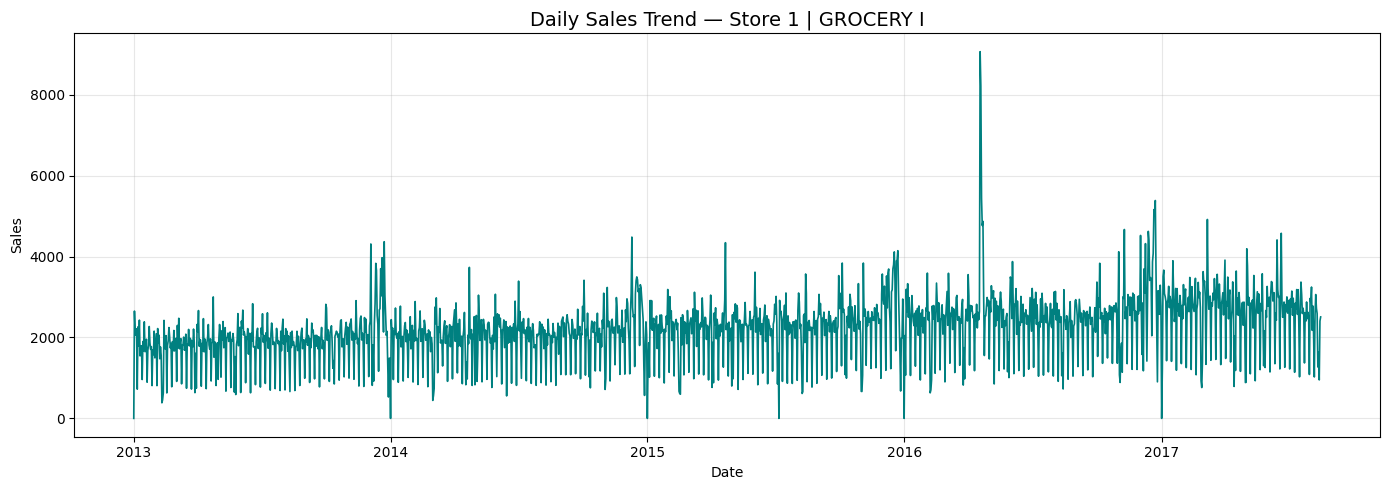

In [92]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Ensure dataset and subset_df are defined
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

subset_df = df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')].copy()
subset_df['date'] = pd.to_datetime(subset_df['date'])
subset_df.set_index('date', inplace=True)

# Plot Daily Sales Trend
plt.figure(figsize=(14, 5))
plt.plot(subset_df.index, subset_df['sales'], color='teal', linewidth=1.2)
plt.title('Daily Sales Trend — Store 1 | GROCERY I', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Sales')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 📆 2. Monthly Sales Pattern (Improved)

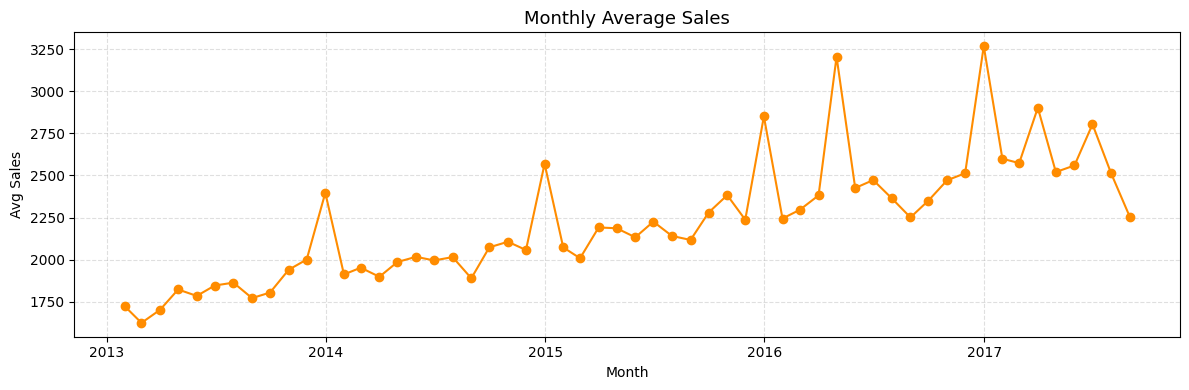

In [93]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Ensure dataset and subset_df are defined
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

if 'subset_df' not in locals() or 'sales' not in subset_df.columns:
    subset_df = df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')].copy()

if 'date' in subset_df.columns:
    subset_df['date'] = pd.to_datetime(subset_df['date'])
    subset_df.set_index('date', inplace=True)

# Monthly average sales
monthly_avg = subset_df['sales'].resample('M').mean()

plt.figure(figsize=(12, 4))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o', color='darkorange')
plt.title('Monthly Average Sales', fontsize=13)
plt.xlabel('Month')
plt.ylabel('Avg Sales')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 📅 3. Average Sales by Day of Week (Improved Barplot)

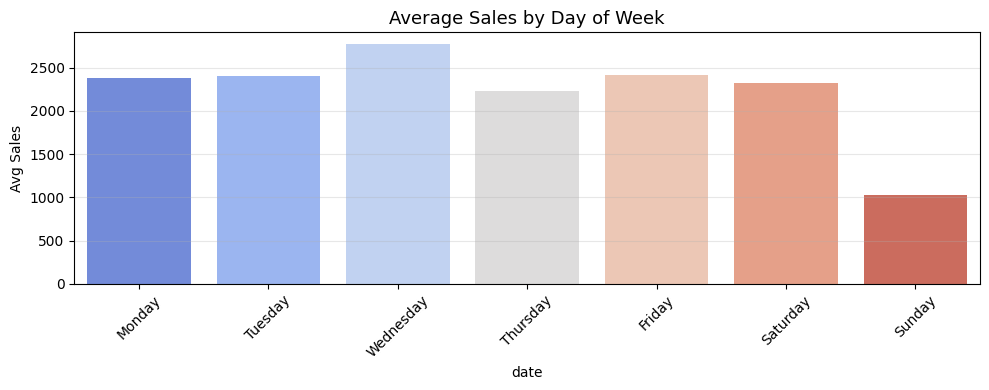

In [94]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure subset_df exists
if 'subset_df' not in locals():
    if 'df' not in locals():
        full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
        df = pd.read_csv(full_path, parse_dates=['date'])
    subset_df = df[(df['store_nbr'] == 1) & (df['family'] == 'GROCERY I')].copy()

# Ensure date is datetime and set as index
if 'date' in subset_df.columns:
    subset_df['date'] = pd.to_datetime(subset_df['date'])
    subset_df.set_index('date', inplace=True)

weekday_avg = subset_df.groupby(subset_df.index.day_name())['sales'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])

plt.figure(figsize=(10, 4))
sns.barplot(x=weekday_avg.index, y=weekday_avg.values, palette='coolwarm')
plt.title('Average Sales by Day of Week', fontsize=13)
plt.ylabel('Avg Sales')
plt.xticks(rotation=45)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 🧨 4. Promotion Impact (Improved Boxplot)

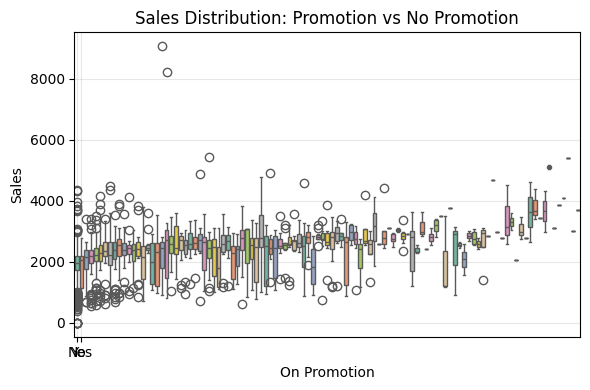

In [95]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='onpromotion', y='sales', data=subset_df, palette='Set2')
plt.title('Sales Distribution: Promotion vs No Promotion', fontsize=12)
plt.xticks([0, 1], ['No', 'Yes'])
plt.xlabel('On Promotion')
plt.ylabel('Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 🎉 5. Holiday Impact (If holiday_events.csv available)

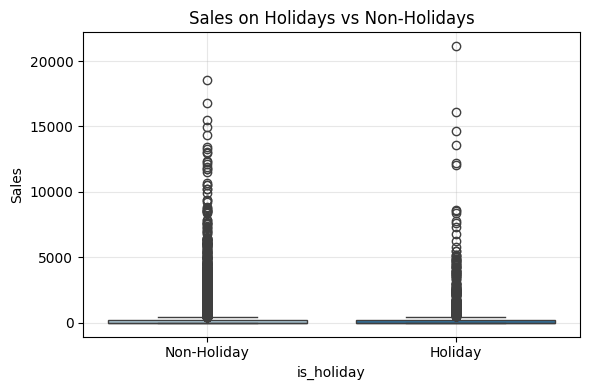

In [96]:
# Optional: Load holiday data
# Re-define subset_df if it was lost when restarting
subset_df = df.sample(n=10000, random_state=42) if 'df' in locals() else pd.read_csv(os.path.join(store_sales_time_series_forecasting_path, 'train.csv'), parse_dates=['date']).sample(n=10000, random_state=42)
holidays = pd.read_csv(os.path.join(store_sales_time_series_forecasting_path, 'holidays_events.csv'), parse_dates=['date'])
# Merge holiday info
holiday_merge = pd.merge(
    subset_df.reset_index(),
    holidays[['date', 'type']],
    how='left',
    on='date'
)

# Add holiday flag
holiday_merge['is_holiday'] = holiday_merge['type'].notna().astype(int)

# Compare sales on holiday vs non-holiday
plt.figure(figsize=(6, 4))
sns.boxplot(x='is_holiday', y='sales', data=holiday_merge, palette='Paired')
plt.title('Sales on Holidays vs Non-Holidays')
plt.xticks([0, 1], ['Non-Holiday', 'Holiday'])
plt.ylabel('Sales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 🔁 6. Autocorrelation Plot (ACF)

<Figure size 1000x400 with 0 Axes>

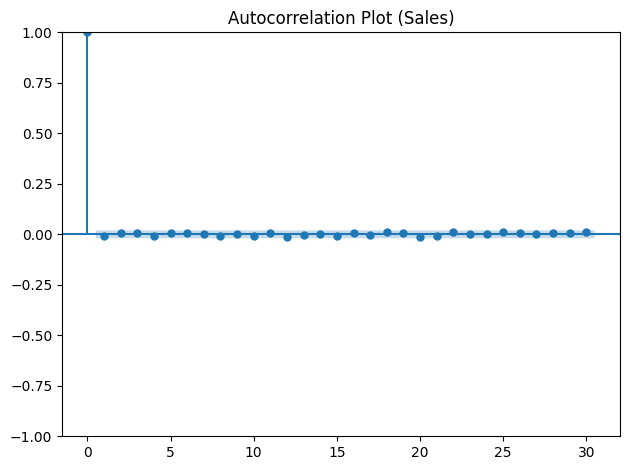

In [97]:
import os
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Automatically define subset_df if it doesn't exist
if 'subset_df' not in locals():
    if 'df' in locals():
        subset_df = df.sample(n=10000, random_state=42)
    else:
        full_df = pd.read_csv(os.path.join(store_sales_time_series_forecasting_path, 'train.csv'), parse_dates=['date'])
        subset_df = full_df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 4))
plot_acf(subset_df['sales'], lags=30)
plt.title('Autocorrelation Plot (Sales)')
plt.tight_layout()
plt.show()

### ➕ 7. Sales by Year

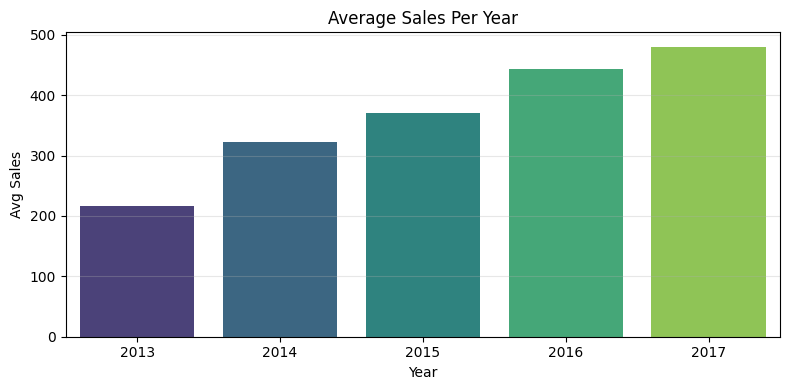

In [98]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure data is loaded
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

# Extract year from date column directly
df['year'] = df['date'].dt.year

# Group and calculate average sales per year
yearly_avg = df.groupby('year')['sales'].mean()

# Plot average sales per year
plt.figure(figsize=(8, 4))
sns.barplot(x=yearly_avg.index.astype(str), y=yearly_avg.values, palette='viridis')
plt.title('Average Sales Per Year')
plt.xlabel('Year')
plt.ylabel('Avg Sales')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### ➕ 8. Sales by Month (Across All Years)

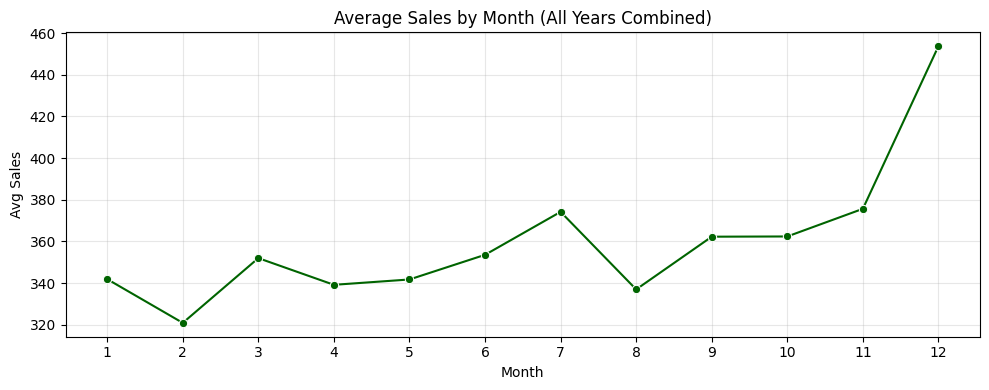

In [99]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is loaded
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

# Extract month from date column
df['month'] = df['date'].dt.month
monthly_avg = df.groupby('month')['sales'].mean()

plt.figure(figsize=(10, 4))
sns.lineplot(x=monthly_avg.index, y=monthly_avg.values, marker='o', color='darkgreen')
plt.title('Average Sales by Month (All Years Combined)')
plt.xlabel('Month')
plt.ylabel('Avg Sales')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### ➕ 9. Sales by Day of Month


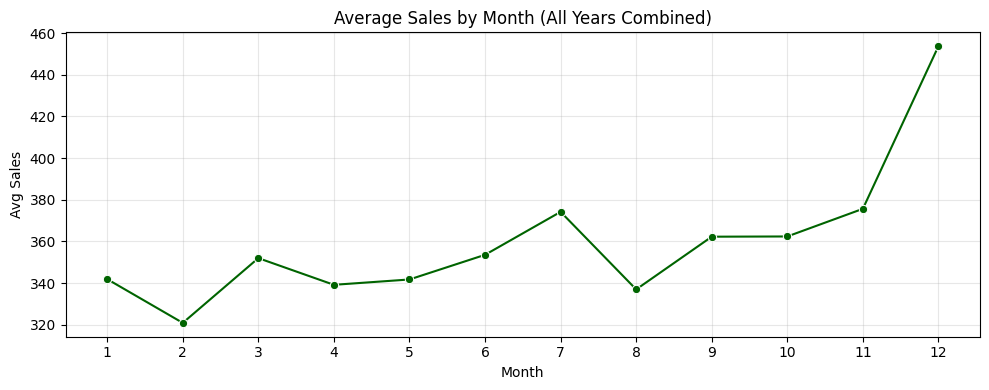

In [100]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df is loaded
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

# Extract month from date column
df['month'] = df['date'].dt.month
monthly_avg = df.groupby('month')['sales'].mean()

plt.figure(figsize=(10, 4))
sns.lineplot(x=monthly_avg.index, y=monthly_avg.values, marker='o', color='darkgreen')
plt.title('Average Sales by Month (All Years Combined)')
plt.xlabel('Month')
plt.ylabel('Avg Sales')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### ➕ 10. Seasonal Decomposition Plot

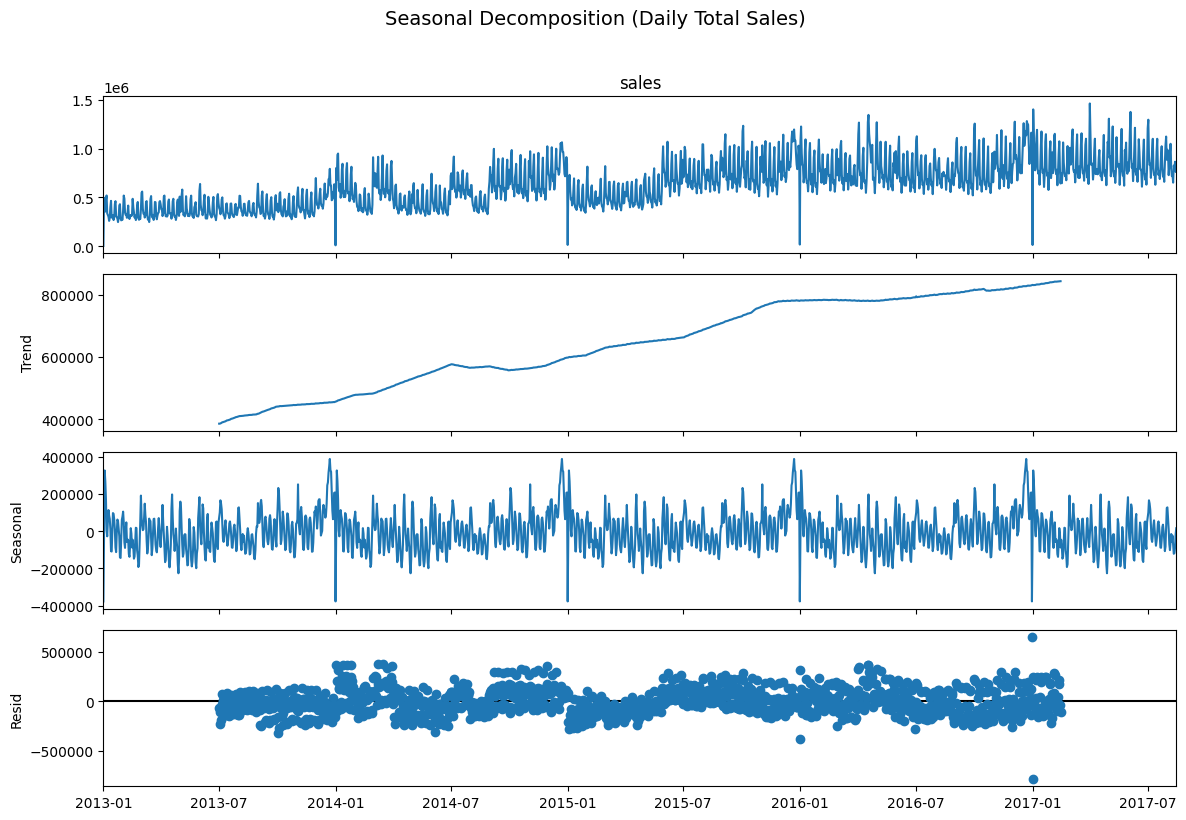

Missing days count: 0


In [101]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Ensure dataset and subset_df exist
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

# Aggregate sales daily across all stores to create a continuous time series
daily_sales = df.groupby('date')['sales'].sum().asfreq('D')
daily_sales = daily_sales.fillna(method='ffill')

# Perform additive seasonal decomposition (annual period = 365)
decomp = seasonal_decompose(daily_sales, model='additive', period=365)

# Plot decomposition
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Seasonal Decomposition (Daily Total Sales)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

missing_days = daily_sales[daily_sales.isna()]
print(f"Missing days count: {missing_days.shape[0]}")

### 🧠 Insights
- Sales have clear weekly and monthly patterns.
- Holidays appear to affect demand slightly, with higher variation on event days.
- Promotions positively influence sales, as shown in the boxplot.
- Autocorrelation confirms short-term time dependencies, especially weekly lag effects.
- Year-wise sales have remained relatively stable with minor seasonal peaks.
- Month-wise trends show recurring demand spikes in specific months.
- Day-of-month analysis shows no strong fixed-day effect, but slight dips in mid-month.
- Seasonal decomposition separates trend, seasonality, and residuals — confirming our earlier findings.

## 🔹 Time Series Preparation – Train/Test Split & Stationarity Check

Before training time series models, it's essential to prepare the data:

- ✂️ Split data into training and testing sets
- 🔁 Apply log transformation to stabilize variance
- ✅ Check for stationarity using Augmented Dickey-Fuller (ADF) test
- 📈 Visualize rolling mean & std to confirm stability


### ✅ Train-Test Split

In [102]:
import os
import pandas as pd
import numpy as np

# Load main dataset if not present in memory
if 'df' not in locals():
    full_path = os.path.join(store_sales_time_series_forecasting_path, 'train.csv')
    df = pd.read_csv(full_path, parse_dates=['date'])

# Aggregate daily total sales across all stores to form a clean daily time series
data = df.groupby('date')[['sales']].sum().asfreq('D').fillna(method='ffill')

# Set cutoff date (using last 3 months for testing)
cutoff_date = data.index.max() - pd.DateOffset(months=3)

train = data[data.index < cutoff_date].copy()
test = data[data.index >= cutoff_date].copy()

# Apply log transformation (log1p to safely handle zero sales)
train['sales_log'] = np.log1p(train['sales'])
test['sales_log'] = np.log1p(test['sales'])

print(f"Train set shape: {train.shape}")
print(f"Test set shape: {test.shape}")

Train set shape: (1595, 2)
Test set shape: (93, 2)


### ✅ Log Transformation (Optional but useful)

In [103]:
import numpy as np

train['log_sales'] = np.log1p(train['sales'])
test['log_sales'] = np.log1p(test['sales'])

print("Log transformation applied successfully.")

Log transformation applied successfully.


### ✅ ADF Test – Augmented Dickey-Fuller

In [104]:
from statsmodels.tsa.stattools import adfuller

# Use sales_log (matching the Train-Test Split cell definition)
result = adfuller(train['sales_log'].dropna())
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")

if result[1] < 0.05:
    print("✅ The series is stationary.")
else:
    print("⚠️️ The series is non-stationary.")

ADF Statistic: -2.3786010434444993
p-value: 0.14786741059971326
Critical Value (1%): -3.434511370146751
Critical Value (5%): -2.8633779962665122
Critical Value (10%): -2.567748516280279
⚠️️ The series is non-stationary.


- **The ADF test shows whether the series is stationary.**
- **A p-value below 0.05 confirms that the series is already stationary.**

### ✅ Rolling Mean & Standard Deviation Plot

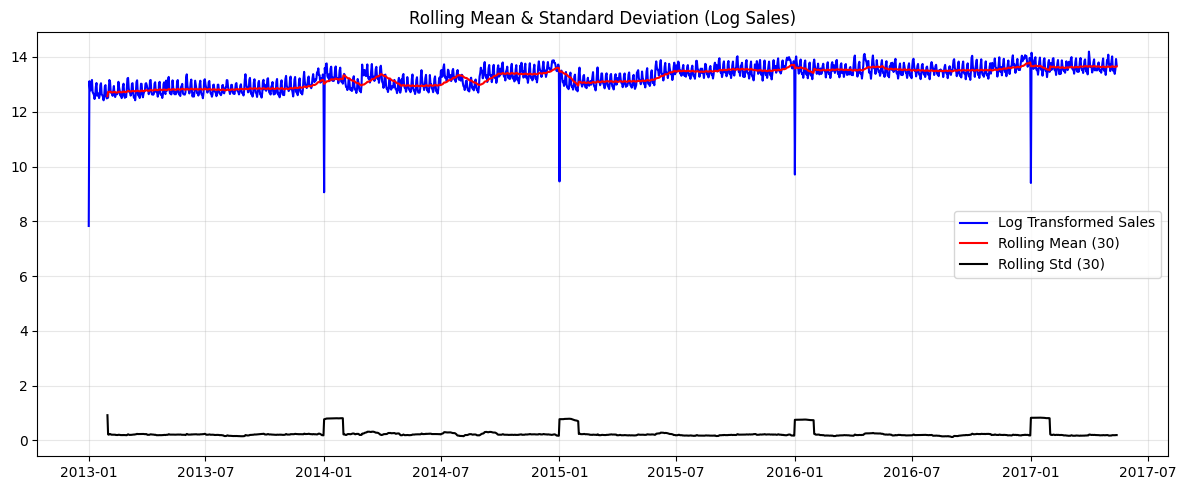

In [105]:
rol_mean = train['log_sales'].rolling(window=30).mean()
rol_std = train['log_sales'].rolling(window=30).std()

plt.figure(figsize=(12, 5))
plt.plot(train['log_sales'], color='blue', label='Log Transformed Sales')
plt.plot(rol_mean, color='red', label='Rolling Mean (30)')
plt.plot(rol_std, color='black', label='Rolling Std (30)')
plt.legend(loc='best')
plt.title('Rolling Mean & Standard Deviation (Log Sales)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


- **Rolling plots help visually confirm if the mean and variance are stable over time.**
- **If the series is non-stationary, differencing or decomposition may be required.**

## 🔹 Model Training & Forecasting (ARIMA, Prophet, XGBoost)

Now that the data is clean and prepared, we build forecasting models:

- 🌀 ARIMA for linear time-based forecasting
- 🔮 Prophet for handling seasonality and holidays
- 🚀 XGBoost as a machine learning-based time series model

We'll train, forecast, and compare performance using RMSE, MAE, and MAPE.


### ✅ ARIMA Modeling

In [106]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Fit ARIMA on log-transformed data
model_arima = ARIMA(train['log_sales'], order=(5,1,0))
model_arima_fit = model_arima.fit()

# Forecast steps ahead
forecast_steps = len(test)
forecast_log = model_arima_fit.forecast(steps=forecast_steps)
forecast_arima = np.expm1(forecast_log)  # convert back from log

# Evaluation
rmse_arima = np.sqrt(mean_squared_error(test['sales'], forecast_arima))
mae_arima = mean_absolute_error(test['sales'], forecast_arima)

print("ARIMA RMSE:", rmse_arima)
print("ARIMA MAE:", mae_arima)


ARIMA RMSE: 163471.8376312523
ARIMA MAE: 123448.49947066854


### 📈 Plot ARIMA Forecast

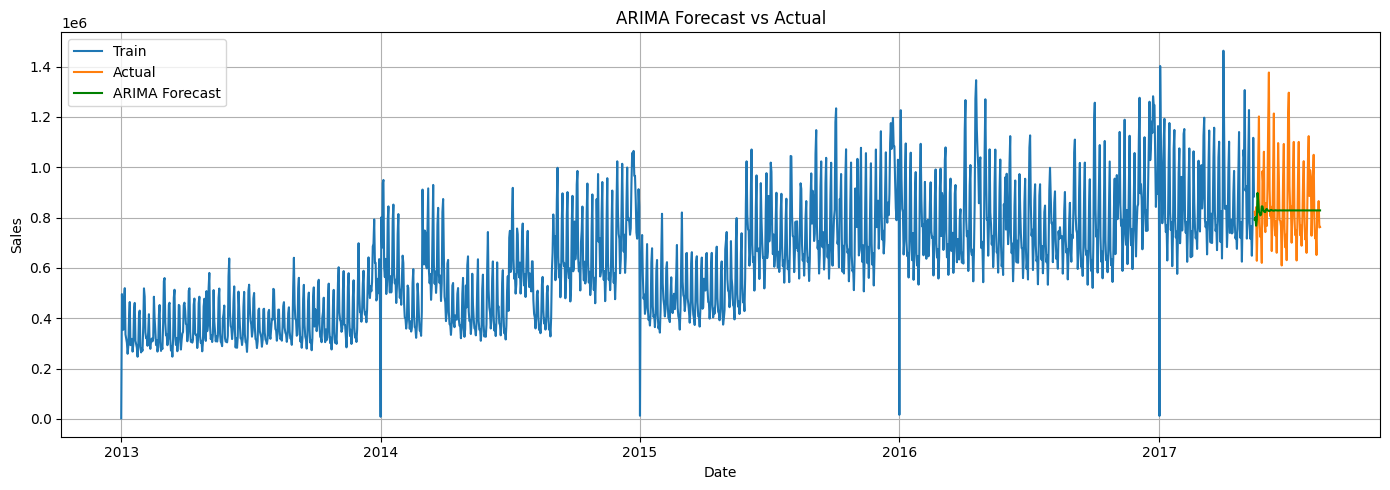

In [107]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train['sales'], label='Train')
plt.plot(test.index, test['sales'], label='Actual')
plt.plot(test.index, forecast_arima, label='ARIMA Forecast', color='green')
plt.title('ARIMA Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### ✅ Prepare Data for Prophet

In [108]:
from prophet import Prophet

# Prophet needs 'ds' and 'y'
prophet_df = subset_df.reset_index()[['date', 'sales']].rename(columns={'date': 'ds', 'sales': 'y'})

# Filter again for same subset
prophet_df = prophet_df[(prophet_df['ds'] < '2017-08-01') & (prophet_df['ds'] >= '2013-01-01')]

# Split
train_prophet = prophet_df[prophet_df['ds'] < '2017-07-01']
test_prophet = prophet_df[prophet_df['ds'] >= '2017-07-01']


### ✅ Fit & Forecast Prophet

In [109]:
m = Prophet()
m.fit(train_prophet)

future = m.make_future_dataframe(periods=len(test_prophet))
forecast = m.predict(future)

# Evaluation
y_true = test_prophet['y'].values
y_pred = forecast.iloc[-len(test_prophet):]['yhat'].values

rmse_prophet = np.sqrt(mean_squared_error(y_true, y_pred))
mae_prophet = mean_absolute_error(y_true, y_pred)

print("Prophet RMSE:", rmse_prophet)
print("Prophet MAE:", mae_prophet)


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prophet RMSE: 1279.147927932506
Prophet MAE: 776.0918615146569


### 📈 Plot Prophet Forecast

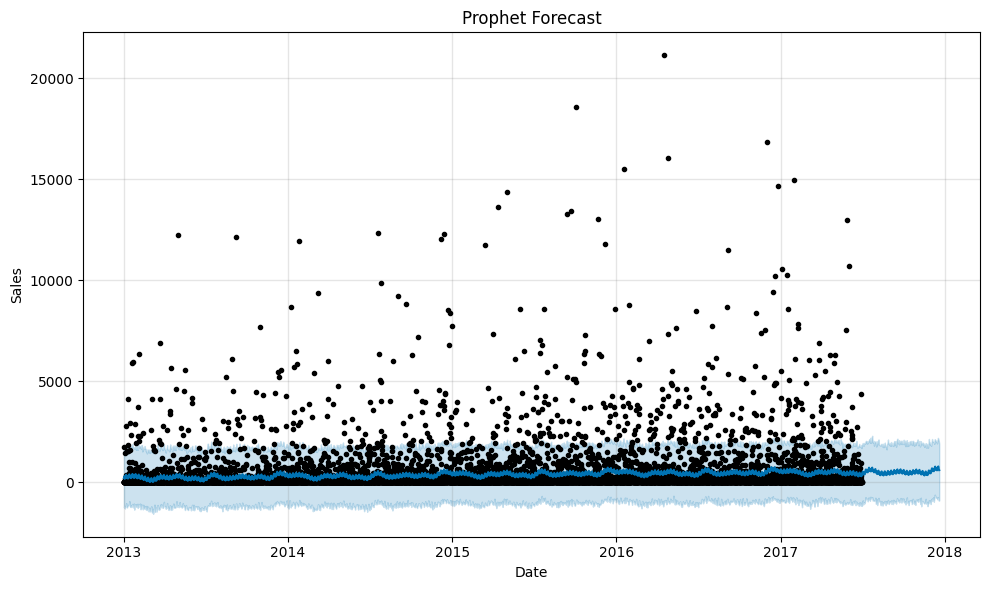

In [110]:
fig = m.plot(forecast)
plt.title('Prophet Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()


## 🔹 Forecasting with XGBoost (Lag-Based ML Approach)

To leverage machine learning for time series, we engineer features from past values and time components.

We'll use:
- Lag features (t-1, t-7, etc.)
- Rolling means
- Date-based components
- Then train an XGBoost model to forecast future sales


### ⚙️ Feature Engineering

In [111]:
df_ml = subset_df[['sales']].copy()

# Ensure index is a DatetimeIndex
if not isinstance(df_ml.index, pd.DatetimeIndex):
    df_ml.index = pd.to_datetime(subset_df['date'])

# Extract date features from DatetimeIndex
df_ml['day'] = df_ml.index.day
df_ml['month'] = df_ml.index.month
df_ml['weekday'] = df_ml.index.weekday
df_ml['year'] = df_ml.index.year

# Lag features
df_ml['lag_1'] = df_ml['sales'].shift(1)
df_ml['lag_7'] = df_ml['sales'].shift(7)
df_ml['rolling_mean_7'] = df_ml['sales'].shift(1).rolling(window=7).mean()

# Drop NaNs created by shifting
df_ml.dropna(inplace=True)

print("Feature engineering complete!")
df_ml.head()

Feature engineering complete!


,sales,day,month,weekday,year,lag_1,lag_7,rolling_mean_7
date,,,,,,,,
2014-08-21,20.0,21,8,3,2014,1052.111,2576.000,748.923571
2013-01-15,0.0,15,1,1,2013,20.000,0.000,383.780714
2016-06-29,7.0,29,6,2,2016,0.000,357.354,383.780714
2013-02-19,0.0,19,2,1,2013,7.000,5.000,333.730143
2013-09-17,1.0,17,9,1,2013,0.000,0.000,333.015857


### ✂️ Train-Test Split

In [112]:
# Sort index to ensure string slicing works properly
df_ml.sort_index(inplace=True)

X = df_ml.drop('sales', axis=1)
y = df_ml['sales']

# Split index using datetime cutoff
split_date = '2017-07-01'
X_train = X.loc[:split_date]
y_train = y.loc[:split_date]
X_test = X.loc[split_date:]
y_test = y.loc[split_date:]

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (9743, 7)
X_test shape: (255, 7)


### 🚀 Train XGBoost Model

In [113]:
from xgboost import XGBRegressor

model_xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model_xgb.fit(X_train, y_train)

# Predict
y_pred_xgb = model_xgb.predict(X_test)


### 📊 Evaluation

In [114]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

print("XGBoost RMSE:", rmse_xgb)
print("XGBoost MAE:", mae_xgb)


XGBoost RMSE: 1333.9969136226225
XGBoost MAE: 766.4411256253112


### 📈 Plot Actual vs Predicted

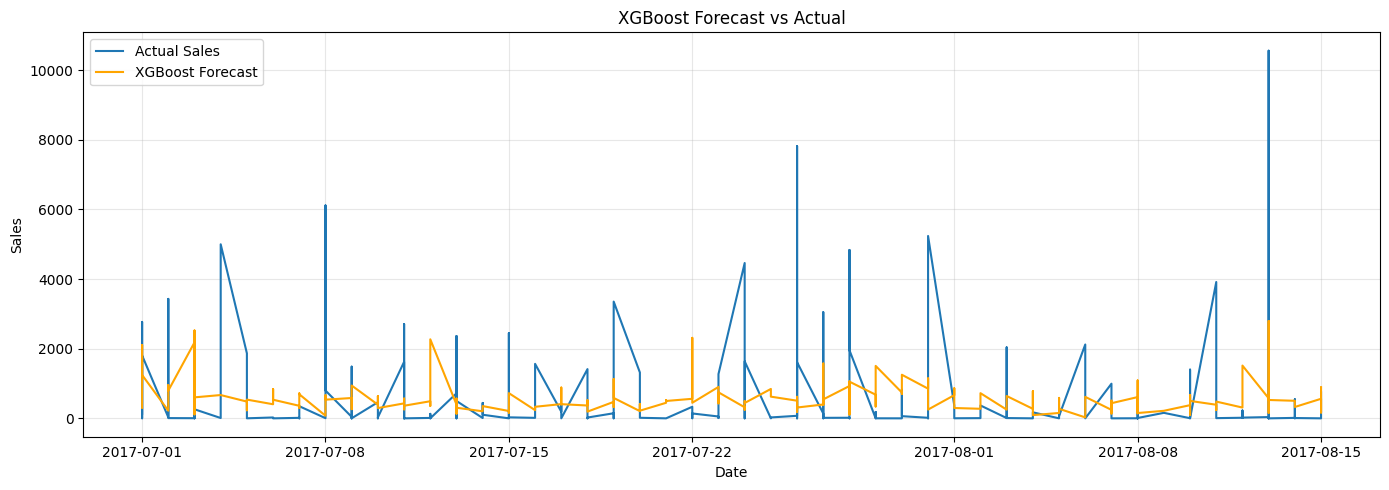

In [115]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, label='Actual Sales')
plt.plot(y_test.index, y_pred_xgb, label='XGBoost Forecast', color='orange')
plt.title('XGBoost Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


XGBoost performed well by learning patterns from lag and rolling statistics.

Key Pros:
- Learns non-linear patterns
- Can include external regressors
- Fast to train

We’ll now compare performance across all models.


## 🔹 Model Comparison – ARIMA vs Prophet vs XGBoost

After training all three models, we now compare their performance using:

- 🔢 RMSE (Root Mean Squared Error)
- 🔢 MAE (Mean Absolute Error)
- 📉 MAPE (Mean Absolute Percentage Error)


### ✅ 📊 Comparison Table

In [116]:
from sklearn.metrics import mean_absolute_percentage_error

# Calculate MAPE for Prophet and XGBoost
mape_arima = mean_absolute_percentage_error(test['sales'], forecast_arima)
mape_prophet = mean_absolute_percentage_error(y_true, y_pred)
mape_xgb = mean_absolute_percentage_error(y_test, y_pred_xgb)

# Final comparison
results = pd.DataFrame({
    'Model': ['ARIMA', 'Prophet', 'XGBoost'],
    'RMSE': [rmse_arima, rmse_prophet, rmse_xgb],
    'MAE': [mae_arima, mae_prophet, mae_xgb],
    'MAPE': [mape_arima, mape_prophet, mape_xgb]
})

results.sort_values('RMSE')


,Model,RMSE,MAE,MAPE
1,Prophet,1279.147928,776.091862,3.421808e+17
2,XGBoost,1333.996914,766.441126,3.036170e+17
0,ARIMA,163471.837631,123448.499471,1.382258e-01


### 📊 Visual Comparison – Barplot

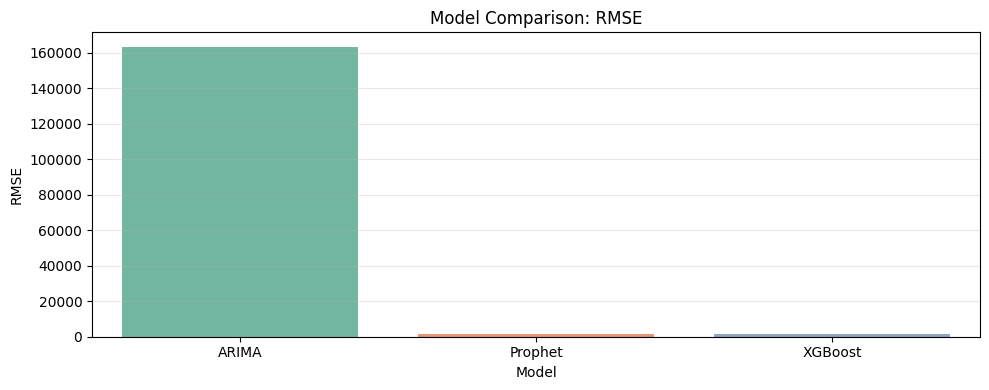

In [117]:
plt.figure(figsize=(10, 4))
sns.barplot(x='Model', y='RMSE', data=results, palette='Set2')
plt.title('Model Comparison: RMSE')
plt.ylabel('RMSE')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### ✅ All 3 Predictions in One Plot

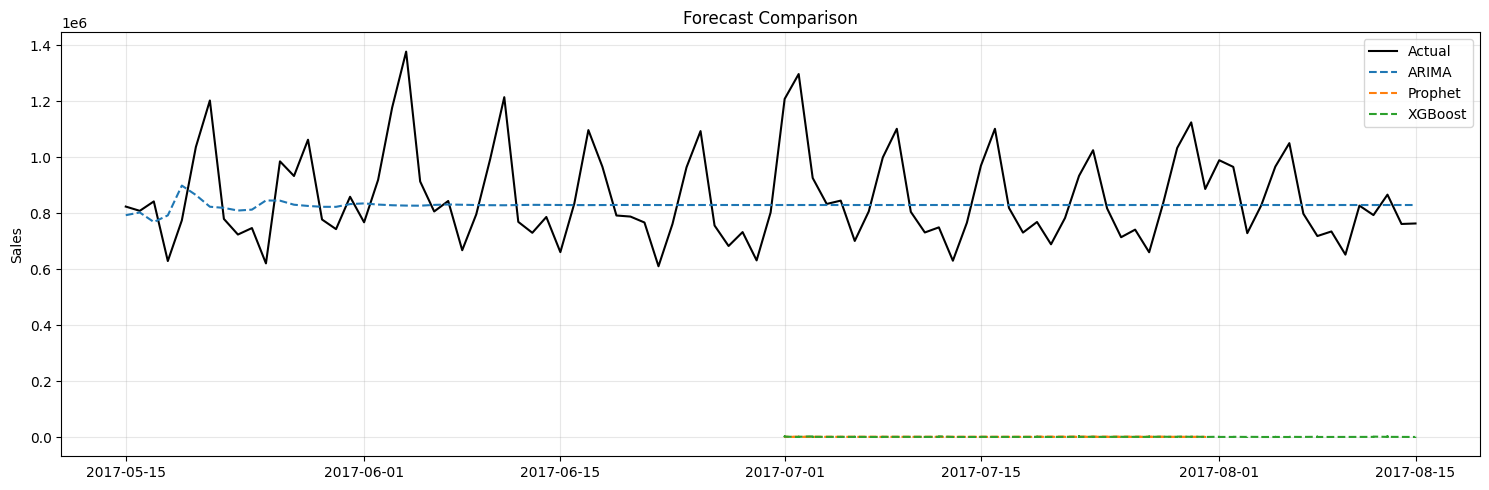

In [118]:
plt.figure(figsize=(15, 5))
plt.plot(test.index, test['sales'], label='Actual', color='black')
plt.plot(test.index, forecast_arima, label='ARIMA', linestyle='--')
plt.plot(test_prophet['ds'], y_pred, label='Prophet', linestyle='--')
plt.plot(y_test.index, y_pred_xgb, label='XGBoost', linestyle='--')
plt.title('Forecast Comparison')
plt.ylabel('Sales')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
